In [6]:
!pip install -q transformers peft

In [1]:

import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU недоступен — можно начать с CPU")


PyTorch: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4


In [2]:
import os
from pathlib import Path
import kagglehub

# Вставь сюда slug найденного на Kaggle датасета VeRi-776
KAGGLE_DATASET = "abhyudaya12/veri-vehicle-re-identification-dataset"
dataset_path = Path(kagglehub.dataset_download(KAGGLE_DATASET))

# Автоматически находим папки image_query и image_test
query_dir = next(dataset_path.rglob("image_query"))
gallery_dir = next(dataset_path.rglob("image_test"))

print("Query dir:", query_dir, "| файлов:", len(list(query_dir.glob("*.jpg"))))
print("Gallery dir:", gallery_dir, "| файлов:", len(list(gallery_dir.glob("*.jpg"))))


Using Colab cache for faster access to the 'veri-vehicle-re-identification-dataset' dataset.
Query dir: /kaggle/input/veri-vehicle-re-identification-dataset/VeRi/image_query | файлов: 1678
Gallery dir: /kaggle/input/veri-vehicle-re-identification-dataset/VeRi/image_test | файлов: 11579


In [3]:
import numpy as np
import torch
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
from tqdm import tqdm

device = "cuda" if torch.cuda.is_available() else "cpu"

class VeRiDataset(Dataset):
    def __init__(self, img_dir, transform=None, limit=None):
        self.paths = sorted(list(Path(img_dir).glob("*.jpg")))
        if limit:
            self.paths = self.paths[:limit]
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        p = self.paths[idx]
        # Формат имен в VeRi-776: 0002_c002_00030600_0.jpg -> vid=2, cam=2
        parts = p.stem.split("_")
        vid = int(parts[0])
        camid = int(parts[1][1:])
        img = Image.open(p).convert("RGB")
        if self.transform:
            img = self.transform(img)
        return img, vid, camid, str(p)

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
])

# Для первого быстрого прогона можно поставить limit=500, для полного замера — None
query_ds = VeRiDataset(query_dir, transform=transform, limit=None)
gallery_ds = VeRiDataset(gallery_dir, transform=transform, limit=None)

query_loader = DataLoader(query_ds, batch_size=64, shuffle=False, num_workers=2)
gallery_loader = DataLoader(gallery_ds, batch_size=64, shuffle=False, num_workers=2)

# Загружаем предобученный Vision Transformer DINOv2 (ViT-B/14)
model = torch.hub.load("facebookresearch/dinov2", "dinov2_vitb14").to(device).eval()

@torch.no_grad()
def extract_features(loader):
    feats, vids, cams, paths = [], [], [], []
    for imgs, v, c, p in tqdm(loader):
        imgs = imgs.to(device)
        with torch.amp.autocast("cuda", enabled=(device == "cuda")):
            emb = model(imgs)
        emb = F.normalize(emb.float(), p=2, dim=1)
        feats.append(emb.cpu().numpy())
        vids.extend(v.numpy())
        cams.extend(c.numpy())
        paths.extend(p)
    return np.vstack(feats), np.array(vids), np.array(cams), paths

q_feats, q_vids, q_cams, q_paths = extract_features(query_loader)
g_feats, g_vids, g_cams, g_paths = extract_features(gallery_loader)

# Матрица косинусного сходства (Query x Gallery)
sim_matrix = q_feats @ g_feats.T

def evaluate_reid(sim_mat, q_vids, q_cams, g_vids, g_cams):
    cmc = np.zeros(10)
    aps = []
    valid_q = 0

    for i in range(len(q_vids)):
        order = np.argsort(-sim_mat[i])
        g_v = g_vids[order]
        g_c = g_cams[order]

        # Исключаем кадры той же машины с той же камеры (официальный протокол VeRi-776)
        keep = ~((g_v == q_vids[i]) & (g_c == q_cams[i]))
        matches = (g_v[keep] == q_vids[i]).astype(np.int32)

        if matches.sum() == 0:
            continue
        valid_q += 1

        # CMC (Rank-1, Rank-5, Rank-10)
        first_match = np.where(matches == 1)[0][0]
        if first_match < 10:
            cmc[first_match:] += 1

        # Average Precision
        cum_matches = np.cumsum(matches)
        precisions = cum_matches / (np.arange(len(matches)) + 1)
        ap = (precisions * matches).sum() / matches.sum()
        aps.append(ap)

    cmc /= valid_q
    return cmc[0] * 100, cmc[4] * 100, np.mean(aps) * 100

r1, r5, mAP = evaluate_reid(sim_matrix, q_vids, q_cams, g_vids, g_cams)
print(f"\nZero-Shot DINOv2 (без маскирования номера):")
print(f"Rank-1: {r1:.2f}% | Rank-5: {r5:.2f}% | mAP: {mAP:.2f}%")


Downloading: "https://github.com/facebookresearch/dinov2/zipball/main" to /root/.cache/torch/hub/main.zip


/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/block.py:40: UserWarning: xFormers is not available (Block)
  warnings.warn("xFormers is not available (Block)")


Downloading: "https://dl.fbaipublicfiles.com/dinov2/dinov2_vitb14/dinov2_vitb14_pretrain.pth" to /root/.cache/torch/hub/checkpoints/dinov2_vitb14_pretrain.pth


100%|██████████| 330M/330M [00:01<00:00, 306MB/s]
100%|██████████| 181/181 [01:37<00:00,  1.86it/s]



Zero-Shot DINOv2 (без маскирования номера):
Rank-1: 13.53% | Rank-5: 24.14% | mAP: 4.77%


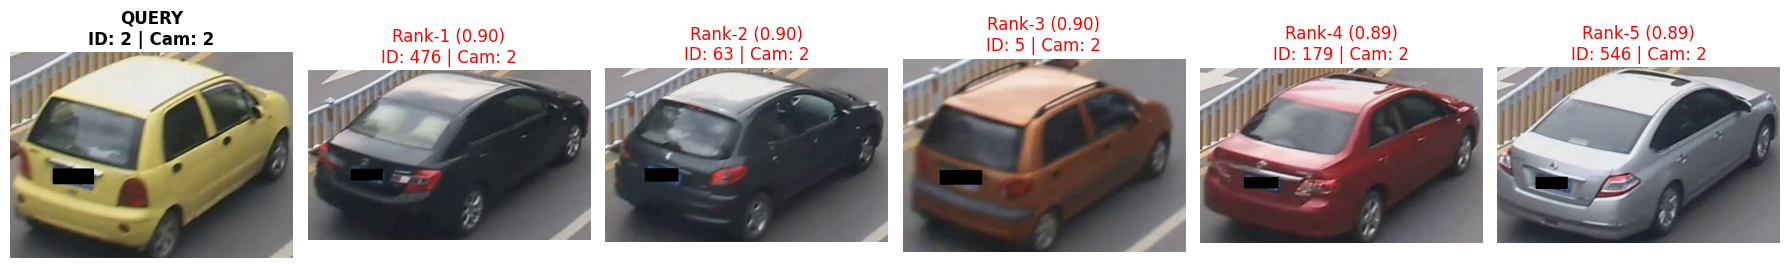

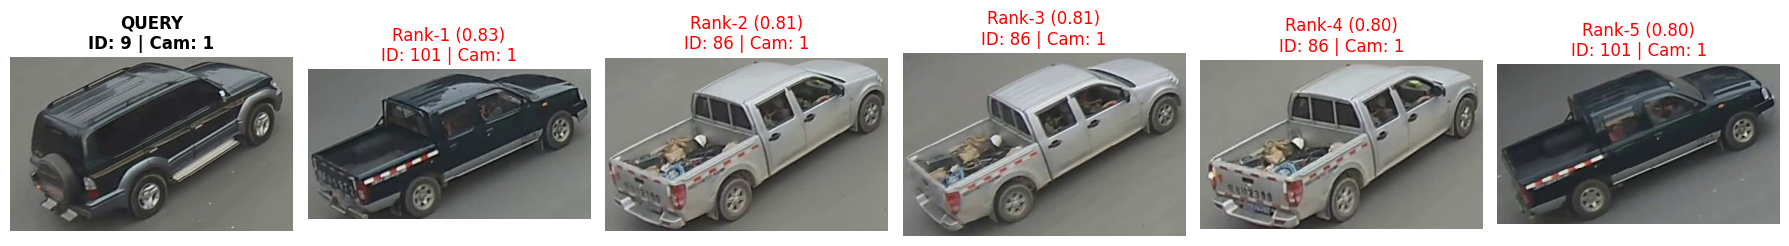

In [4]:
import matplotlib.pyplot as plt

def show_top5(q_idx):
    order = np.argsort(-sim_matrix[q_idx])
    keep = ~((g_vids[order] == q_vids[q_idx]) & (g_cams[order] == q_cams[q_idx]))
    top5_idx = order[keep][:5]

    fig, axes = plt.subplots(1, 6, figsize=(18, 3.5))
    axes[0].imshow(Image.open(q_paths[q_idx]))
    axes[0].set_title(f"QUERY\nID: {q_vids[q_idx]} | Cam: {q_cams[q_idx]}", fontweight="bold")
    axes[0].axis("off")

    for rank, g_idx in enumerate(top5_idx, start=1):
        is_correct = g_vids[g_idx] == q_vids[q_idx]
        color = "green" if is_correct else "red"
        axes[rank].imshow(Image.open(g_paths[g_idx]))
        axes[rank].set_title(
            f"Rank-{rank} ({sim_matrix[q_idx, g_idx]:.2f})\nID: {g_vids[g_idx]} | Cam: {g_cams[g_idx]}",
            color=color
        )
        axes[rank].axis("off")

    plt.tight_layout()
    plt.show()

show_top5(0)
show_top5(25)


In [7]:
import random
from pathlib import Path
from collections import defaultdict
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, Sampler
from torchvision import transforms
from transformers import AutoModel
from peft import LoraConfig, get_peft_model
from PIL import Image
from tqdm import tqdm

train_dir = next(dataset_path.rglob("image_train"))

# Аугментации: флип + цветовые сдвиги + RandomErasing (имитация грязи/бликов)
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    transforms.RandomErasing(p=0.5, scale=(0.02, 0.25)),
])

class VeRiTrainDataset(Dataset):
    def __init__(self, img_dir, transform=None):
        self.paths = sorted(list(Path(img_dir).glob("*.jpg")))
        self.transform = transform
        raw_vids = [int(p.stem.split("_")[0]) for p in self.paths]
        unique_vids = sorted(set(raw_vids))
        self.vid2label = {v: i for i, v in enumerate(unique_vids)}
        self.labels = [self.vid2label[v] for v in raw_vids]
        self.num_classes = len(unique_vids)

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        img = Image.open(self.paths[idx]).convert("RGB")
        if self.transform:
            img = self.transform(img)
        return img, self.labels[idx]

class PKSampler(Sampler):
    """Формирует батчи из P машин по K разных фото каждой машины."""
    def __init__(self, labels, p=16, k=4, passes=4):
        self.p, self.k, self.passes = p, k, passes
        self.index_dict = defaultdict(list)
        for idx, label in enumerate(labels):
            self.index_dict[label].append(idx)
        self.pids = list(self.index_dict.keys())

    def __iter__(self):
        indices = []
        for _ in range(self.passes):
            pids = self.pids.copy()
            random.shuffle(pids)
            for pid in pids:
                pool = self.index_dict[pid]
                selected = random.sample(pool, self.k) if len(pool) >= self.k else random.choices(pool, k=self.k)
                indices.extend(selected)
        return iter(indices)

    def __len__(self):
        return len(self.pids) * self.k * self.passes

class DINOv2LoRAReID(nn.Module):
    def __init__(self, num_classes, r=16):
        super().__init__()
        base = AutoModel.from_pretrained("facebook/dinov2-base")

        # Автоматически находим имена слоев внимания в текущей версии transformers
        linear_names = {
            name.split(".")[-1]
            for name, mod in base.named_modules()
            if isinstance(mod, nn.Linear)
        }
        print("Найденные Linear-слои:", sorted(linear_names))

        if {"query", "value"} <= linear_names:
            targets = ["query", "value"]
        elif {"q_proj", "v_proj"} <= linear_names:
            targets = ["q_proj", "v_proj"]
        elif "qkv" in linear_names:
            targets = ["qkv"]
        else:
            targets = "all-linear"
        print("Выбранные target_modules для LoRA:", targets)

        lora_cfg = LoraConfig(
            r=r,
            lora_alpha=r * 2,
            target_modules=targets,
            lora_dropout=0.1,
        )
        self.backbone = get_peft_model(base, lora_cfg)
        self.feat_dim = base.config.hidden_size
        self.bnneck = nn.BatchNorm1d(self.feat_dim)
        self.bnneck.bias.requires_grad_(False)
        self.classifier = nn.Linear(self.feat_dim, num_classes, bias=False)

    def forward(self, x):
        feat = self.backbone(pixel_values=x).last_hidden_state[:, 0]
        bn_feat = self.bnneck(feat)
        if self.training:
            logits = self.classifier(bn_feat)
            return feat, logits
        return F.normalize(bn_feat.float(), p=2, dim=1)

def batch_hard_triplet_loss(feats, labels, margin=0.3):
    feats = F.normalize(feats.float(), p=2, dim=1)
    dist = 1.0 - torch.matmul(feats, feats.t())
    pos_mask = labels.unsqueeze(0) == labels.unsqueeze(1)
    hardest_pos = (dist * pos_mask.float()).max(dim=1)[0]
    hardest_neg = (dist + 1e5 * pos_mask.float()).min(dim=1)[0]
    return F.relu(hardest_pos - hardest_neg + margin).mean()

train_ds = VeRiTrainDataset(train_dir, transform=train_transform)
sampler = PKSampler(train_ds.labels, p=16, k=4, passes=4)
train_loader = DataLoader(train_ds, batch_size=64, sampler=sampler, num_workers=2, drop_last=True)

reid_model = DINOv2LoRAReID(num_classes=train_ds.num_classes, r=16).to(device)
reid_model.backbone.print_trainable_parameters()

ce_criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer = torch.optim.AdamW(
    [p for p in reid_model.parameters() if p.requires_grad],
    lr=4e-4, weight_decay=1e-4
)
EPOCHS = 8
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
scaler = torch.amp.GradScaler("cuda")

for epoch in range(1, EPOCHS + 1):
    reid_model.train()
    total_loss = 0.0
    pbar = tqdm(train_loader, desc=f"Epoch {epoch}/{EPOCHS}")
    for imgs, labels in pbar:
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer.zero_grad()
        with torch.amp.autocast("cuda"):
            feat, logits = reid_model(imgs)
            loss = ce_criterion(logits, labels) + batch_hard_triplet_loss(feat, labels, margin=0.3)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        total_loss += loss.item()
        pbar.set_postfix(loss=f"{loss.item():.3f}")
    scheduler.step()
    print(f"Epoch {epoch} avg loss: {total_loss / len(train_loader):.4f}")


Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

Найденные Linear-слои: ['fc1', 'fc2', 'k_proj', 'o_proj', 'q_proj', 'v_proj']
Выбранные target_modules для LoRA: ['q_proj', 'v_proj']


ImportError: Found an incompatible version of torchao. Found version 0.10.0, but only versions above 0.16.0 are supported

In [8]:
import importlib
import peft.import_utils
import peft.tuners.lora.torchao as peft_torchao

# Отключаем проверку конфликтного torchao, он для обычной LoRA не нужен
peft.import_utils.is_torchao_available = lambda: False
peft_torchao.is_torchao_available = lambda: False
importlib.invalidate_caches()

reid_model = DINOv2LoRAReID(num_classes=train_ds.num_classes, r=16).to(device)
reid_model.backbone.print_trainable_parameters()

ce_criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer = torch.optim.AdamW(
    [p for p in reid_model.parameters() if p.requires_grad],
    lr=4e-4, weight_decay=1e-4
)
EPOCHS = 8
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
scaler = torch.amp.GradScaler("cuda")

for epoch in range(1, EPOCHS + 1):
    reid_model.train()
    total_loss = 0.0
    pbar = tqdm(train_loader, desc=f"Epoch {epoch}/{EPOCHS}")
    for imgs, labels in pbar:
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer.zero_grad()
        with torch.amp.autocast("cuda"):
            feat, logits = reid_model(imgs)
            loss = ce_criterion(logits, labels) + batch_hard_triplet_loss(feat, labels, margin=0.3)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        total_loss += loss.item()
        pbar.set_postfix(loss=f"{loss.item():.3f}")
    scheduler.step()
    print(f"Epoch {epoch} avg loss: {total_loss / len(train_loader):.4f}")


Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

Найденные Linear-слои: ['fc1', 'fc2', 'k_proj', 'o_proj', 'q_proj', 'v_proj']
Выбранные target_modules для LoRA: ['q_proj', 'v_proj']
trainable params: 589,824 || all params: 87,170,304 || trainable%: 0.6766


Epoch 1/8: 100%|██████████| 144/144 [02:00<00:00,  1.20it/s, loss=5.471]


Epoch 1 avg loss: 6.1517


Epoch 2/8: 100%|██████████| 144/144 [01:46<00:00,  1.35it/s, loss=3.895]


Epoch 2 avg loss: 4.4805


... (8 outputs left out)

Epoch 7/8: 100%|██████████| 144/144 [01:34<00:00,  1.53it/s, loss=1.874]


Epoch 7 avg loss: 1.8818


Epoch 8/8: 100%|██████████| 144/144 [01:34<00:00,  1.53it/s, loss=1.844]

Epoch 8 avg loss: 1.8342


100%|██████████| 181/181 [00:56<00:00,  3.22it/s]



Fine-Tuned DINOv2 + LoRA (без номеров):
Rank-1: 86.89% | Rank-5: 93.92% | mAP: 60.79%


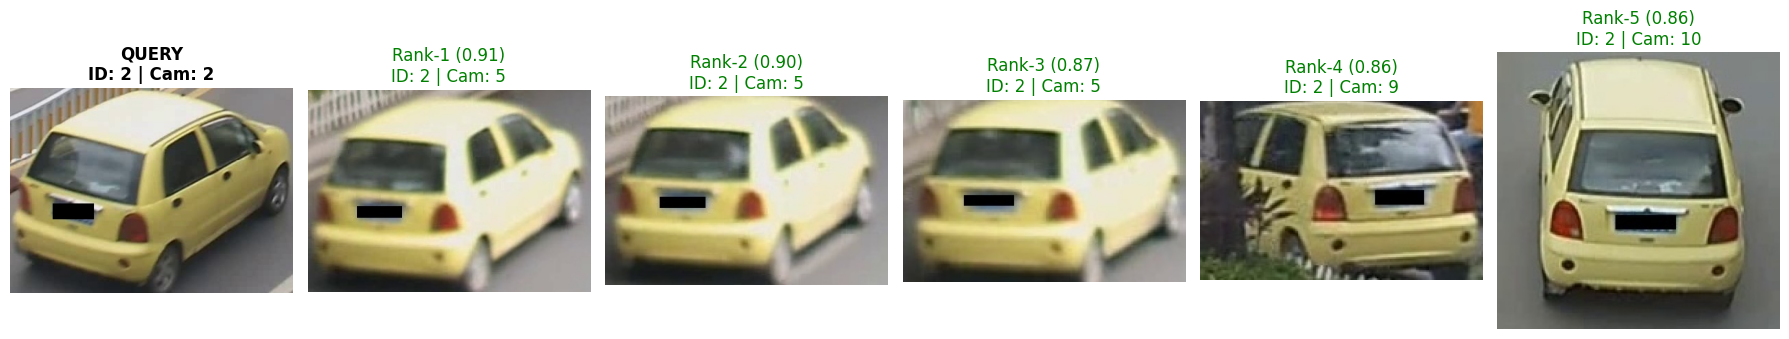

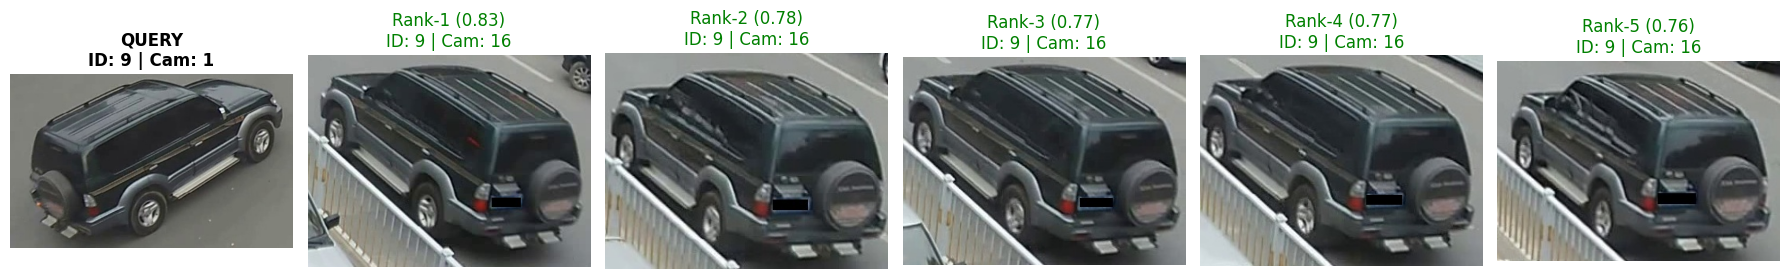

In [9]:
@torch.no_grad()
def extract_reid_features(model_eval, loader):
    model_eval.eval()
    feats, vids, cams, paths = [], [], [], []
    for imgs, v, c, p in tqdm(loader):
        imgs = imgs.to(device)
        with torch.amp.autocast("cuda"):
            emb = model_eval(imgs)
        feats.append(emb.cpu().numpy())
        vids.extend(v.numpy())
        cams.extend(c.numpy())
        paths.extend(p)
    return np.vstack(feats), np.array(vids), np.array(cams), paths

q_feats_ft, q_vids, q_cams, q_paths = extract_reid_features(reid_model, query_loader)
g_feats_ft, g_vids, g_cams, g_paths = extract_reid_features(reid_model, gallery_loader)

sim_matrix = q_feats_ft @ g_feats_ft.T
r1_ft, r5_ft, mAP_ft = evaluate_reid(sim_matrix, q_vids, q_cams, g_vids, g_cams)

print(f"\nFine-Tuned DINOv2 + LoRA (без номеров):")
print(f"Rank-1: {r1_ft:.2f}% | Rank-5: {r5_ft:.2f}% | mAP: {mAP_ft:.2f}%")

# Сохраняем веса, чтобы не обучать заново при сбросе Colab
torch.save(reid_model.state_dict(), "dinov2_lora_veri776.pth")

show_top5(0)
show_top5(25)


In [10]:
from google.colab import files
files.download("dinov2_lora_veri776.pth")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [11]:
from tqdm import tqdm

def k_reciprocal_rerank(q_feats, g_feats, k1=20, k2=6, lambda_value=0.3):
    all_feats = np.vstack([q_feats, g_feats]).astype(np.float32)
    q_num = q_feats.shape[0]
    all_num = all_feats.shape[0]

    # Матрица расстояний на GPU
    t_feats = torch.from_numpy(all_feats).to(device)
    original_dist = (2.0 - 2.0 * torch.clamp(t_feats @ t_feats.T, -1.0, 1.0)).cpu().numpy()
    del t_feats
    torch.cuda.empty_cache()

    original_dist = np.transpose(original_dist / (np.max(original_dist, axis=0) + 1e-12))
    V = np.zeros_like(original_dist, dtype=np.float32)
    initial_rank = np.argsort(original_dist).astype(np.int32)

    for i in tqdm(range(all_num), desc="k-Reciprocal neighbors"):
        forward_k = initial_rank[i, :k1 + 1]
        backward_k = initial_rank[forward_k, :k1 + 1]
        fi = np.where(backward_k == i)[0]
        k_recip = forward_k[fi]
        k_recip_exp = k_recip
        for cand in k_recip:
            cand_f = initial_rank[cand, :int(np.around(k1 / 2)) + 1]
            cand_b = initial_rank[cand_f, :int(np.around(k1 / 2)) + 1]
            cand_recip = cand_f[np.where(cand_b == cand)[0]]
            if len(np.intersect1d(cand_recip, k_recip)) > (2.0 / 3.0) * len(cand_recip):
                k_recip_exp = np.append(k_recip_exp, cand_recip)
        k_recip_exp = np.unique(k_recip_exp)
        weight = np.exp(-original_dist[i, k_recip_exp])
        V[i, k_recip_exp] = weight / np.sum(weight)

    if k2 != 1:
        V_qe = np.zeros_like(V, dtype=np.float32)
        for i in range(all_num):
            V_qe[i, :] = np.mean(V[initial_rank[i, :k2], :], axis=0)
        V = V_qe
        del V_qe

    inv_index = [np.where(V[:, i] != 0)[0] for i in range(all_num)]
    jaccard_dist = np.zeros((q_num, all_num), dtype=np.float32)
    for i in tqdm(range(q_num), desc="Jaccard distance"):
        temp_min = np.zeros((1, all_num), dtype=np.float32)
        ind_nz = np.where(V[i, :] != 0)[0]
        for idx in ind_nz:
            imgs = inv_index[idx]
            temp_min[0, imgs] += np.minimum(V[i, idx], V[imgs, idx])
        jaccard_dist[i] = 1.0 - temp_min / (2.0 - temp_min)

    final_dist = jaccard_dist * (1.0 - lambda_value) + original_dist[:q_num, :] * lambda_value
    return -final_dist[:, q_num:]  # со знаком минус, чтобы использовать как сходство

sim_rerank = k_reciprocal_rerank(q_feats_ft, g_feats_ft)
r1_rr, r5_rr, mAP_rr = evaluate_reid(sim_rerank, q_vids, q_cams, g_vids, g_cams)
print(f"\nDINOv2 + LoRA + k-Reciprocal Re-ranking:")
print(f"Rank-1: {r1_rr:.2f}% | Rank-5: {r5_rr:.2f}% | mAP: {mAP_rr:.2f}%")


Jaccard distance: 100%|██████████| 1678/1678 [00:01<00:00, 1481.61it/s]



DINOv2 + LoRA + k-Reciprocal Re-ranking:
Rank-1: 89.27% | Rank-5: 91.66% | mAP: 64.60%


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Downloading: "https://github.com/cvg/LightGlue/releases/download/v0.1_arxiv/superpoint_v1.pth" to /root/.cache/torch/hub/checkpoints/superpoint_v1.pth


100%|██████████| 4.96M/4.96M [00:00<00:00, 292MB/s]


Downloading: "https://github.com/cvg/LightGlue/releases/download/v0.1_arxiv/superpoint_lightglue.pth" to /root/.cache/torch/hub/checkpoints/superpoint_lightglue_v0-1_arxiv.pth


100%|██████████| 45.3M/45.3M [00:00<00:00, 373MB/s]


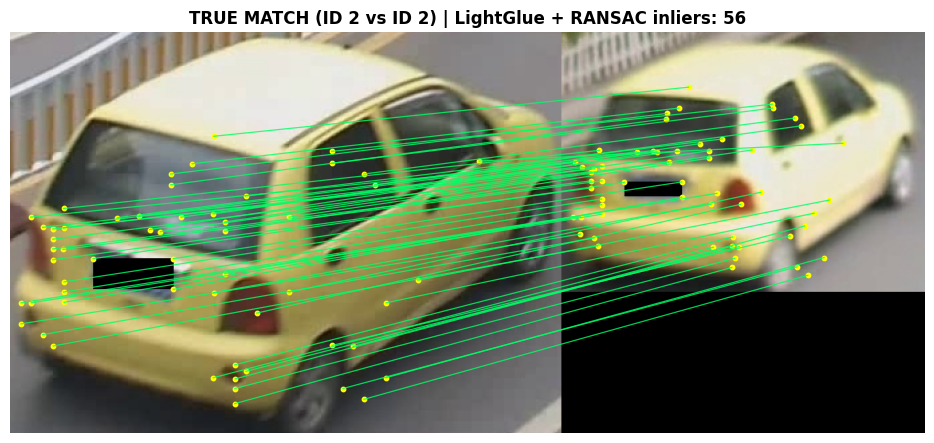

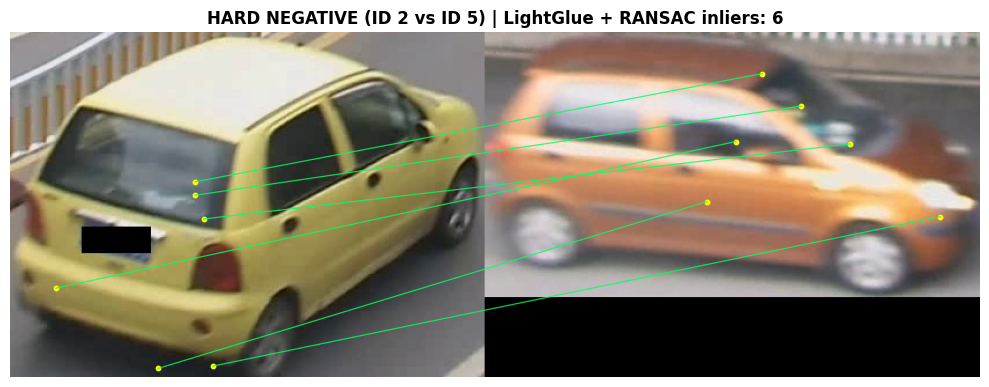

6

In [12]:
!pip install -q git+https://github.com/cvg/LightGlue.git

import cv2
from lightglue import LightGlue, SuperPoint, match_pair
from lightglue.utils import load_image

extractor = SuperPoint(max_num_keypoints=512).eval().to(device)
matcher = LightGlue(features="superpoint").eval().to(device)

def verify_and_plot_pair(path0, path1, title_prefix=""):
    img0 = load_image(path0).to(device)
    img1 = load_image(path1).to(device)
    with torch.inference_mode():
        feats0, feats1, matches01 = match_pair(extractor, matcher, img0, img1)

    matches = matches01["matches"]
    kpts0 = feats0["keypoints"][matches[..., 0]].cpu().numpy()
    kpts1 = feats1["keypoints"][matches[..., 1]].cpu().numpy()

    # Геометрическая проверка RANSAC (отсеиваем случайные совпадения)
    inliers = np.ones(len(kpts0), dtype=bool)
    if len(kpts0) >= 8:
        _, mask = cv2.findFundamentalMat(kpts0, kpts1, cv2.FM_RANSAC, 3.0)
        if mask is not None:
            inliers = mask.ravel().astype(bool)

    n_inliers = int(inliers.sum())
    im0 = np.array(Image.open(path0).convert("RGB"))
    im1 = np.array(Image.open(path1).convert("RGB"))

    # Склеиваем два фото рядом
    h = max(im0.shape[0], im1.shape[0])
    canvas = np.zeros((h, im0.shape[1] + im1.shape[1], 3), dtype=np.uint8)
    canvas[:im0.shape[0], :im0.shape[1]] = im0
    canvas[:im1.shape[0], im0.shape[1]:] = im1

    plt.figure(figsize=(10, 4.5))
    plt.imshow(canvas)
    offset_x = im0.shape[1]
    for p0, p1 in zip(kpts0[inliers], kpts1[inliers]):
        plt.plot([p0[0], p1[0] + offset_x], [p0[1], p1[1]], color="#00ff66", linewidth=0.9, alpha=0.8)
        plt.scatter([p0[0], p1[0] + offset_x], [p0[1], p1[1]], color="yellow", s=10)
    plt.title(f"{title_prefix} | LightGlue + RANSAC inliers: {n_inliers}", fontsize=12, fontweight="bold")
    plt.axis("off")
    plt.tight_layout()
    plt.show()
    return n_inliers

# Берем запрос q_idx=0 и находим его лучшего реального совпавшего кандидата и лучшего "двойника"
q_idx = 0
order = np.argsort(-sim_matrix[q_idx])
keep = ~((g_vids[order] == q_vids[q_idx]) & (g_cams[order] == q_cams[q_idx]))
valid_order = order[keep]

pos_idx = next(i for i in valid_order if g_vids[i] == q_vids[q_idx])
neg_idx = next(i for i in valid_order if g_vids[i] != q_vids[q_idx])

verify_and_plot_pair(q_paths[q_idx], g_paths[pos_idx], f"TRUE MATCH (ID {q_vids[q_idx]} vs ID {g_vids[pos_idx]})")
verify_and_plot_pair(q_paths[q_idx], g_paths[neg_idx], f"HARD NEGATIVE (ID {q_vids[q_idx]} vs ID {g_vids[neg_idx]})")


In [13]:
import copy, time, os

def benchmark_model(m, use_fp16=False, name=""):
    m.eval()
    dummy = torch.randn(32, 3, 224, 224, device=device)
    if use_fp16:
        m = m.half()
        dummy = dummy.half()

    # Прогрев GPU
    with torch.no_grad():
        for _ in range(5):
            _ = m(dummy)
    torch.cuda.synchronize()

    # Замер времени (30 батчей по 32 кадра = 960 кадров)
    t0 = time.perf_counter()
    with torch.no_grad():
        for _ in range(30):
            _ = m(dummy)
    torch.cuda.synchronize()
    elapsed = time.perf_counter() - t0

    ms_per_img = (elapsed / (30 * 32)) * 1000
    fps = (30 * 32) / elapsed

    # Размер весов на диске (без тренировочного классификатора)
    tmp_path = f"/tmp/{name}.pth"
    torch.save({k: v for k, v in m.state_dict().items() if "classifier" not in k}, tmp_path)
    size_mb = os.path.getsize(tmp_path) / (1024 * 1024)

    # Проверка точности на query + gallery
    def _extract(loader):
        feats = []
        with torch.no_grad():
            for imgs, _, _, _ in loader:
                imgs = imgs.to(device)
                if use_fp16:
                    imgs = imgs.half()
                feats.append(m(imgs).float().cpu().numpy())
        return np.vstack(feats)

    qf = _extract(query_loader)
    gf = _extract(gallery_loader)
    r1, r5, mAP = evaluate_reid(qf @ gf.T, q_vids, q_cams, g_vids, g_cams)
    print(f"{name:22s} | Size: {size_mb:6.1f} MB | {ms_per_img:5.2f} ms/img ({fps:6.1f} FPS) | Rank-1: {r1:.2f}% | mAP: {mAP:.2f}%")

# 1. Обычный FP32 с LoRA-адаптерами
m_fp32 = copy.deepcopy(reid_model).float().to(device)
benchmark_model(m_fp32, use_fp16=False, name="FP32_LoRA_Unmerged")

# 2. Вшитые веса LoRA (FP32)
m_merged = copy.deepcopy(reid_model).float().to(device)
m_merged.backbone = m_merged.backbone.merge_and_unload()
benchmark_model(m_merged, use_fp16=False, name="FP32_LoRA_Merged")

# 3. Вшитые веса LoRA + FP16 квантизация
m_fp16 = copy.deepcopy(m_merged).to(device)
benchmark_model(m_fp16, use_fp16=True, name="FP16_LoRA_Merged")


FP32_LoRA_Unmerged     | Size:  332.6 MB | 13.96 ms/img (  71.6 FPS) | Rank-1: 86.89% | mAP: 60.79%
FP32_LoRA_Merged       | Size:  330.4 MB | 15.75 ms/img (  63.5 FPS) | Rank-1: 86.89% | mAP: 60.79%
FP16_LoRA_Merged       | Size:  165.2 MB |  3.48 ms/img ( 287.4 FPS) | Rank-1: 86.89% | mAP: 60.79%


In [15]:
import os
from google.colab import files

os.makedirs("figures", exist_ok=True)

# 1. Сохраняем объединенные FP16-веса без тренировочного классификатора
m_export = copy.deepcopy(reid_model).float()
m_export.backbone = m_export.backbone.merge_and_unload()
m_export = m_export.half()
export_state = {k: v for k, v in m_export.state_dict().items() if "classifier" not in k}
torch.save(export_state, "dinov2_lora_fp16_merged.pth")

# 2. Сохраняем графики LightGlue (True Match и Hard Negative) в 300 DPI
def save_lightglue_fig(path0, path1, title_prefix, out_name):
    img0, img1 = load_image(path0).to(device), load_image(path1).to(device)
    with torch.inference_mode():
        f0, f1, m01 = match_pair(extractor, matcher, img0, img1)
    m = m01["matches"]
    k0 = f0["keypoints"][m[..., 0]].cpu().numpy()
    k1 = f1["keypoints"][m[..., 1]].cpu().numpy()
    inliers = np.ones(len(k0), dtype=bool)
    if len(k0) >= 8:
        _, mask = cv2.findFundamentalMat(k0, k1, cv2.FM_RANSAC, 3.0)
        if mask is not None:
            inliers = mask.ravel().astype(bool)
    im0, im1 = np.array(Image.open(path0).convert("RGB")), np.array(Image.open(path1).convert("RGB"))
    h = max(im0.shape[0], im1.shape[0])
    canvas = np.zeros((h, im0.shape[1] + im1.shape[1], 3), dtype=np.uint8)
    canvas[:im0.shape[0], :im0.shape[1]] = im0
    canvas[:im1.shape[0], im0.shape[1]:] = im1
    plt.figure(figsize=(10, 4.5))
    plt.imshow(canvas)
    for p0, p1 in zip(k0[inliers], k1[inliers]):
        plt.plot([p0[0], p1[0] + im0.shape[1]], [p0[1], p1[1]], color="#00ff66", lw=0.9, alpha=0.8)
        plt.scatter([p0[0], p1[0] + im0.shape[1]], [p0[1], p1[1]], color="yellow", s=10)
    plt.title(f"{title_prefix} | LightGlue + RANSAC inliers: {int(inliers.sum())}", fontweight="bold")
    plt.axis("off")
    plt.tight_layout()
    plt.savefig(f"figures/{out_name}", dpi=300, bbox_inches="tight")
    plt.close()

save_lightglue_fig(q_paths[q_idx], g_paths[pos_idx], f"TRUE MATCH (ID {q_vids[q_idx]})", "lightglue_true_match.png")
save_lightglue_fig(q_paths[q_idx], g_paths[neg_idx], f"HARD NEGATIVE (ID {q_vids[q_idx]} vs {g_vids[neg_idx]})", "lightglue_hard_negative.png")

!zip -q report_figures.zip figures/*.png
files.download("report_figures.zip")
files.download("dinov2_lora_fp16_merged.pth")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>